# 1. Persiapan Lingkungan dan Dataset

# 2. Persiapan Data dan Preprocessing

In [1]:
# 1. Environment Setup & Dataset Verification

import json
import random
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from tqdm.auto import tqdm



DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "document-image-classification-sd234504"
)

OUTPUT_DIR = Path("/kaggle/working")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoint"

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("=" * 50)
print("NOTEBOOK 02 - MODELLING")
print("=" * 50)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Number of classes:", train_df["label"].nunique())

assert len(train_df) == 32003
assert len(test_df) == 7994
assert train_df["label"].nunique() == 16

print("\nEnvironment & dataset verification successful!")

NOTEBOOK 02 - MODELLING
Device: cuda
GPU: Tesla T4
Training samples: 32003
Testing samples: 7994
Number of classes: 16

Environment & dataset verification successful!


## 2.1 Pembagian Data Training dan Validasi Terstratifikasi

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["label"],
    random_state=SEED
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("=" * 50)
print("STRATIFIED DATA SPLITTING")
print("=" * 50)

print("Train samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Total:", len(train_data) + len(val_data))

print("\nTrain class distribution:")
display(train_data["class_name"].value_counts())

print("\nValidation class distribution:")
display(val_data["class_name"].value_counts())

assert set(train_data["id"]).isdisjoint(
    set(val_data["id"])
)

print("\nNo overlapping IDs between train and validation.")

STRATIFIED DATA SPLITTING
Train samples: 25602
Validation samples: 6401
Total: 32003

Train class distribution:


class_name
scientific_publication    1645
resume                    1623
handwritten               1621
file_folder               1617
advertisement             1610
email                     1610
form                      1604
budget                    1603
scientific_report         1599
memo                      1595
presentation              1594
invoice                   1586
specification             1582
letter                    1578
news_article              1577
questionnaire             1558
Name: count, dtype: int64


Validation class distribution:


class_name
scientific_publication    411
resume                    406
file_folder               405
handwritten               405
email                     403
advertisement             402
budget                    401
form                      401
scientific_report         400
memo                      399
presentation              398
invoice                   396
specification             396
letter                    394
news_article              394
questionnaire             390
Name: count, dtype: int64


No overlapping IDs between train and validation.


## 2.2 Resize Gambar dengan Padding

In [3]:
IMG_SIZE = 224

class ResizeWithPadding:
    """
    Mengubah ukuran gambar tanpa mengubah rasio aspek.

    Gambar diskalakan agar muat ke dalam kanvas persegi,
    kemudian ditambahkan padding putih.

    Args:
        size (int): Ukuran sisi akhir gambar.

    Returns:
        PIL.Image.Image: Gambar RGB persegi.
    """

    def __init__(self, size=224):
        self.size = size

    def __call__(self, image):
        image = image.convert("RGB")

        # Mempertahankan aspect ratio
        img = ImageOps.contain(
            image,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        # Padding putih
        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            (255, 255, 255)
        )

        x = (self.size - img.width) // 2
        y = (self.size - img.height) // 2

        canvas.paste(img, (x, y))

        return canvas


print("ResizeWithPadding berhasil dibuat.")

ResizeWithPadding berhasil dibuat.


## 2.3 Augmentasi dan Normalisasi Gambar

In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),

    transforms.RandomRotation(
        degrees=3,
        fill=(255, 255, 255)
    ),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

val_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transform ready.")
print("Validation transform ready.")

Training transform ready.
Validation transform ready.


## 2.4 Dataset PyTorch Kustom

In [5]:
class DocumentDataset(Dataset):
    """
    Dataset PyTorch untuk klasifikasi gambar dokumen TIFF.

    Args:
        dataframe (pd.DataFrame):
            Metadata gambar yang memiliki filename dan label.
        data_dir (Path):
            Direktori utama dataset kompetisi.
        transform (callable, optional):
            Transformasi preprocessing gambar.
    """

    def __init__(
        self,
        dataframe,
        data_dir,
        transform=None
    ):
        self.df = dataframe.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self):
        """Mengembalikan jumlah sampel dataset."""
        return len(self.df)

    def __getitem__(self, idx):
        """
        Membaca gambar dan label berdasarkan indeks.

        Args:
            idx (int): Indeks sampel.

        Returns:
            tuple: Tensor gambar dan label integer.
        """
        row = self.df.iloc[idx]

        # Metadata: train/resume/nama.tif
        # Path aktual: train/train/resume/nama.tif
        image_path = (
            self.data_dir / "train" / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])

        return image, label


train_dataset = DocumentDataset(
    dataframe=train_data,
    data_dir=DATA_DIR,
    transform=train_transform
)

val_dataset = DocumentDataset(
    dataframe=val_data,
    data_dir=DATA_DIR,
    transform=val_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

# Uji satu gambar
sample_image, sample_label = train_dataset[0]

print("\nSample tensor shape:", sample_image.shape)
print("Sample label:", sample_label)

assert sample_image.shape == (3, 224, 224)
assert 0 <= sample_label < 16

print("\nDataset berhasil diuji!")

Train dataset: 25602
Validation dataset: 6401

Sample tensor shape: torch.Size([3, 224, 224])
Sample label: 1

Dataset berhasil diuji!


## 2.5 DataLoader PyTorch

In [6]:
BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch labels shape:", labels.shape)

assert images.shape == (32, 3, 224, 224)
assert labels.min() >= 0
assert labels.max() < 16

print("\nDataLoader siap untuk training.")

Train batches: 801
Validation batches: 201

Batch image shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])

DataLoader siap untuk training.


## 2.6 Visualisasi Preprocessing

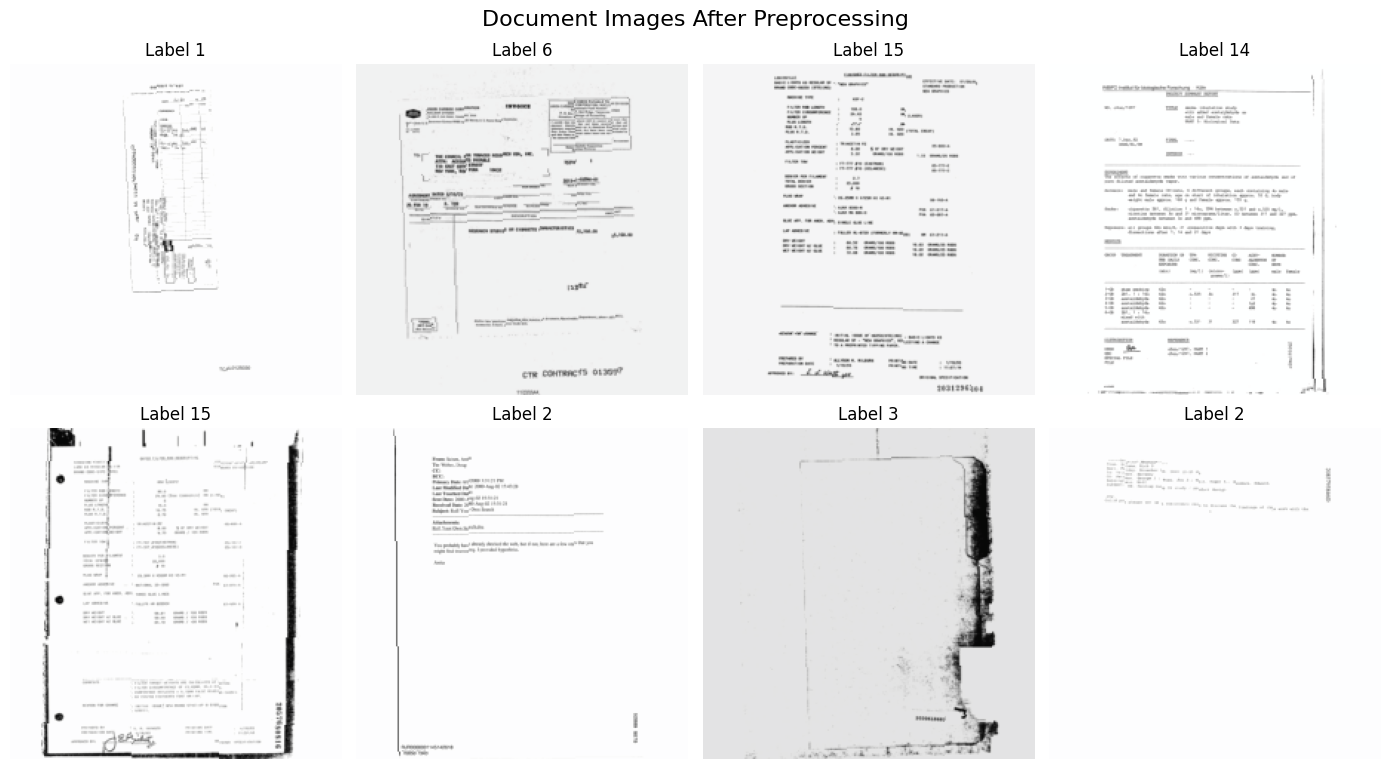

In [7]:
def denormalize_image(tensor):
    """
    Mengembalikan tensor ter-normalisasi ke skala RGB.

    Args:
        tensor (torch.Tensor): Tensor gambar [C,H,W].

    Returns:
        np.ndarray: Gambar RGB dengan nilai 0-1.
    """
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)

    image = tensor.permute(1, 2, 0).numpy()
    image = image * std + mean

    return np.clip(image, 0, 1)


fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for i in range(8):
    image, label = train_dataset[i]

    ax = axes.flat[i]
    ax.imshow(denormalize_image(image))
    ax.set_title(f"Label {label}")
    ax.axis("off")

plt.suptitle(
    "Document Images After Preprocessing",
    fontsize=16
)
plt.tight_layout()
plt.show()

## 2.7 Pemeriksaan Integritas Gambar

In [13]:
def audit_image_files(dataframe, data_dir):
    """
    Memeriksa integritas gambar TIFF dalam dataframe.

    Args:
        dataframe (pd.DataFrame): Metadata gambar.
        data_dir (Path): Direktori dataset kompetisi.

    Returns:
        tuple: Dataframe file valid dan dataframe file rusak.
    """
    valid_indices = []
    bad_records = []

    for idx, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc="Checking TIFF integrity"
    ):
        path = Path(data_dir) / "train" / row["filename"]

        try:
            with Image.open(path) as img:
                img.load()
                if img.width <= 0 or img.height <= 0:
                    raise ValueError("Invalid image dimensions")

            valid_indices.append(idx)

        except Exception as error:
            bad_records.append({
                "id": row["id"],
                "filename": row["filename"],
                "label": row["label"],
                "error_type": type(error).__name__,
                "error": str(error)
            })

    valid_df = dataframe.loc[
        valid_indices
    ].reset_index(drop=True)

    bad_df = pd.DataFrame(
        bad_records,
        columns=[
            "id", "filename", "label",
            "error_type", "error"
        ]
    )

    return valid_df, bad_df


# Audit seluruh data training berlabel
clean_train_df, corrupted_df = audit_image_files(
    train_df,
    DATA_DIR
)

print("\n" + "=" * 50)
print("IMAGE INTEGRITY REPORT")
print("=" * 50)

print("Original images :", len(train_df))
print("Valid images    :", len(clean_train_df))
print("Corrupted images:", len(corrupted_df))

display(corrupted_df.head(20))

# Simpan daftar gambar rusak
corrupted_df.to_csv(
    "/kaggle/working/corrupted_images.csv",
    index=False
)

print("\nAudit selesai.")

Checking TIFF integrity:   0%|          | 0/32003 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))



IMAGE INTEGRITY REPORT
Original images : 32003
Valid images    : 32002
Corrupted images: 1


,id,filename,label,error_type,error
0,train_08795,train/scientific_publication/2500126531_250012...,13,UnidentifiedImageError,cannot identify image file '/kaggle/input/comp...



Audit selesai.


## 2.8 Pembersihan Dataset dan Pembagian Ulang

In [14]:
# Memisahkan training dan validation
train_data, val_data = train_test_split(
    clean_train_df,
    test_size=0.20,
    stratify=clean_train_df["label"],
    random_state=SEED
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

# Membuat ulang Dataset
train_dataset = DocumentDataset(
    dataframe=train_data,
    data_dir=DATA_DIR,
    transform=train_transform
)

val_dataset = DocumentDataset(
    dataframe=val_data,
    data_dir=DATA_DIR,
    transform=val_transform
)

# Membuat ulang DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("=" * 50)
print("CLEAN DATASET READY")
print("=" * 50)

print("Training samples  :", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Total valid images:", len(clean_train_df))

print("Training batches  :", len(train_loader))
print("Validation batches:", len(val_loader))

# Pemeriksaan batch
images, labels = next(iter(train_loader))

print("\nBatch shape:", images.shape)
print("Labels shape:", labels.shape)

assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)

print("\nDataset siap digunakan untuk training!")

CLEAN DATASET READY
Training samples  : 25601
Validation samples: 6401
Total valid images: 32002
Training batches  : 801
Validation batches: 201

Batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])

Dataset siap digunakan untuk training!


# 3. Pengembangan Model

## 3.1 Arsitektur EfficientNet-B0

In [15]:
NUM_CLASSES = 16

# Memuat model pretrained ImageNet
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Mengubah classifier menjadi 16 kelas
num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)

# Informasi arsitektur
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 50)
print("MODEL INFORMATION")
print("=" * 50)

print("Architecture: EfficientNet-B0")
print("Pretrained: ImageNet")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Classifier:", model.classifier)

# Memastikan model menghasilkan 16 output
model.eval()

with torch.no_grad():
    dummy_input = torch.randn(
        1, 3, IMG_SIZE, IMG_SIZE
    ).to(device)

    dummy_output = model(dummy_input)

print("Output shape:", dummy_output.shape)

assert dummy_output.shape == (1, 16)

print("\nModel berhasil dibuat!")

MODEL INFORMATION
Architecture: EfficientNet-B0
Pretrained: ImageNet
Number of classes: 16
Device: cuda
Total parameters: 4,028,044
Trainable parameters: 4,028,044
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=16, bias=True)
)
Output shape: torch.Size([1, 16])

Model berhasil dibuat!


## 3.2 Konfigurasi Pelatihan

In [16]:
LEARNING_RATE = 1e-4
EPOCHS = 10
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("Training configuration ready!")
print("Loss:", criterion)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Weight decay:", WEIGHT_DECAY)

Training configuration ready!
Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 10
Weight decay: 0.0001


## 3.3 Pelatihan Model

In [17]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):
    """
    Melatih model selama satu epoch menggunakan PyTorch.

    Args:
        model (nn.Module): Model klasifikasi dokumen.
        loader (DataLoader): DataLoader training.
        criterion (nn.Module): Fungsi loss.
        optimizer (Optimizer): Optimizer model.
        device (torch.device): CPU atau GPU.
        scaler (GradScaler): Pengelola AMP gradient scaling.

    Returns:
        tuple: Rata-rata training loss dan accuracy (%).
    """
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

        progress.set_postfix(
            loss=f"{running_loss / total:.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    return running_loss / total, 100 * correct / total


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):
    """
    Mengevaluasi model pada data validation.

    Args:
        model (nn.Module): Model klasifikasi dokumen.
        loader (DataLoader): DataLoader validation.
        criterion (nn.Module): Fungsi loss.
        device (torch.device): CPU atau GPU.

    Returns:
        tuple: Rata-rata validation loss dan accuracy (%).
    """
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

        progress.set_postfix(
            loss=f"{running_loss / total:.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    return running_loss / total, 100 * correct / total


print("Training and validation functions ready!")

Training and validation functions ready!


## 3.4 Mixed Precision dan Early Stopping

In [18]:
# AMP untuk GPU Tesla T4
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

# Konfigurasi early stopping
PATIENCE = 3
MIN_DELTA = 0.001

best_val_acc = -1.0
best_epoch = 0
epochs_without_improvement = 0

# Penyimpanan hasil

CHECKPOINT_DIR = Path("/kaggle/working/checkpoint")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "best_efficientnet_b0.pth"
)

LAST_CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "last_training_checkpoint.pth"
)

# Riwayat training
history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": []
}

print("AMP enabled:", use_amp)
print("Early stopping patience:", PATIENCE)
print("Maximum epochs:", EPOCHS)
print("Best model path:", BEST_MODEL_PATH)

AMP enabled: True
Early stopping patience: 3
Maximum epochs: 10
Best model path: /kaggle/working/checkpoint/best_efficientnet_b0.pth


## 3.5 Fine-Tuning EfficientNet-B0

In [19]:
print("=" * 60)
print("START TRAINING - EFFICIENTNET-B0")
print("=" * 60)

training_start = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 50)

    # 1. Training
    train_loss, train_acc = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        scaler=scaler
    )

    # 2. Validation
    val_loss, val_acc = validate_one_epoch(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=device
    )

    # 3. Learning rate saat epoch ini
    current_lr = optimizer.param_groups[0]["lr"]

    # 4. Simpan training history
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["learning_rate"].append(current_lr)

    # 5. Perbarui learning rate
    scheduler.step()

    # 6. Simpan best model
    if val_acc > best_val_acc + MIN_DELTA:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("New best model saved!")
    else:
        epochs_without_improvement += 1

    # 7. Simpan checkpoint untuk melanjutkan training
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_acc": best_val_acc,
            "best_epoch": best_epoch,
            "history": history,
            "epochs_without_improvement":
                epochs_without_improvement,
        },
        LAST_CHECKPOINT_PATH
    )

    # 8. Simpan CSV history
    pd.DataFrame(history).to_csv(
        "/kaggle/working/training_history.csv",
        index=False
    )

    # 9. Tampilkan hasil epoch
    elapsed = time.time() - epoch_start

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Acc  : {train_acc:.2f}%")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Acc    : {val_acc:.2f}%")
    print(f"Best Val   : {best_val_acc:.2f}%")
    print(f"LR         : {current_lr:.7f}")
    print(f"Time       : {elapsed / 60:.2f} min")

    # 10. Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch + 1}."
        )
        break

total_time = time.time() - training_start

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.2f}%")
print(f"Total training time: {total_time / 60:.2f} min")
print(f"Best model: {BEST_MODEL_PATH}")

START TRAINING - EFFICIENTNET-B0

Epoch 1/10
--------------------------------------------------


Training:   0%|          | 0/801 [00:00<?, ?it/s]

Validation:   0%|          | 0/201 [00:00<?, ?it/s]

New best model saved!
Train Loss : 1.3835
Train Acc  : 58.86%
Val Loss   : 0.8742
Val Acc    : 73.36%
Best Val   : 73.36%
LR         : 0.0001000
Time       : 3.25 min

Epoch 2/10
--------------------------------------------------


Training:   0%|          | 0/801 [00:00<?, ?it/s]

Validation:   0%|          | 0/201 [00:00<?, ?it/s]

... (21 outputs left out)

Train Loss : 0.2746
Train Acc  : 91.58%
Val Loss   : 0.6201
Val Acc    : 82.74%
Best Val   : 82.92%
LR         : 0.0000095
Time       : 3.37 min

Epoch 10/10
--------------------------------------------------


Training:   0%|          | 0/801 [00:00<?, ?it/s]

Validation:   0%|          | 0/201 [00:00<?, ?it/s]

New best model saved!
Train Loss : 0.2650
Train Acc  : 91.88%
Val Loss   : 0.6131
Val Acc    : 83.25%
Best Val   : 83.25%
LR         : 0.0000024
Time       : 3.39 min

TRAINING COMPLETED
Best epoch: 10
Best validation accuracy: 83.25%
Total training time: 33.72 min
Best model: /kaggle/working/checkpoint/best_efficientnet_b0.pth


# 4. Evaluasi Model

## 4.1 Visualisasi Riwayat Pelatihan

,epoch,train_loss,train_acc,val_loss,val_acc,learning_rate
0,1,1.383547,58.864888,0.874169,73.363537,0.000100
1,2,0.833620,74.946291,0.713053,78.987658,0.000098
2,3,0.671797,79.703918,0.655693,80.799875,0.000090
3,4,0.562161,83.063162,0.625127,81.971567,0.000079
4,5,0.474832,85.430257,0.617534,81.862209,0.000065
5,6,0.398069,87.605953,0.617440,82.815185,0.000050
6,7,0.344566,89.441819,0.611967,82.924543,0.000035
7,8,0.309281,90.562869,0.610348,82.862053,0.000021
8,9,0.274649,91.578454,0.620070,82.737072,0.000010
9,10,0.264981,91.883130,0.613076,83.252617,0.000002


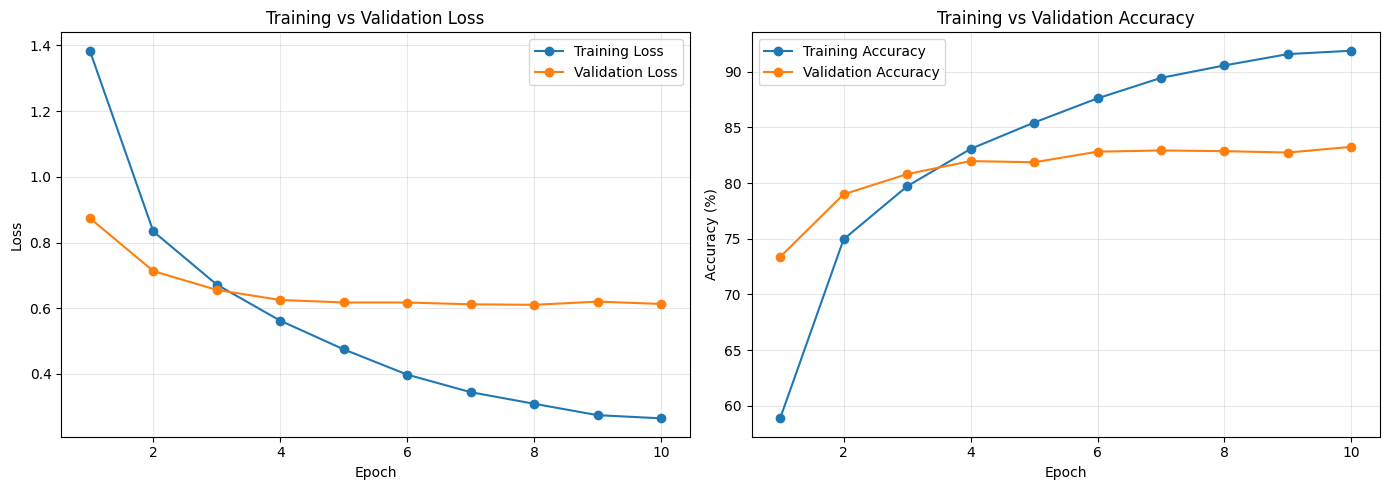

TRAINING SUMMARY
Best epoch: 10
Best Validation Accuracy: 83.25%
Final Training Accuracy: 91.88%

Grafik berhasil disimpan!


In [20]:
# Lokasi penyimpanan hasil evaluasi
EVAL_DIR = Path("/kaggle/working/evaluation")
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Membaca riwayat dari CSV hasil training
history_df = pd.read_csv(
    "/kaggle/working/training_history.csv"
)

display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik training dan validation loss
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Grafik training dan validation accuracy
axes[1].plot(
    history_df["epoch"],
    history_df["train_acc"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    EVAL_DIR / "training_curves.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

best_row = history_df.loc[
    history_df["val_acc"].idxmax()
]

print("=" * 50)
print("TRAINING SUMMARY")
print("=" * 50)

print("Best epoch:", int(best_row["epoch"]))
print(f'Best Validation Accuracy: {best_row["val_acc"]:.2f}%')
print(f'Final Training Accuracy: {history_df["train_acc"].iloc[-1]:.2f}%')

print("\nGrafik berhasil disimpan!")

## 4.2 Laporan Klasifikasi dan Confusion Matrix

Evaluating validation data:   0%|          | 0/201 [00:00<?, ?it/s]

EFFICIENTNET-B0 VALIDATION EVALUATION
Validation Accuracy: 83.25%

Classification Report:


,precision,recall,f1-score,support
advertisement,0.8909,0.8731,0.8819,402.0000
budget,0.7488,0.7581,0.7534,401.0000
email,0.9589,0.9851,0.9718,403.0000
file_folder,0.8845,0.9457,0.9141,405.0000
form,0.6551,0.7057,0.6795,401.0000
handwritten,0.8938,0.9556,0.9236,405.0000
invoice,0.8579,0.7929,0.8241,396.0000
letter,0.7788,0.8756,0.8244,394.0000
memo,0.9216,0.8246,0.8704,399.0000
news_article,0.8740,0.8096,0.8406,394.0000


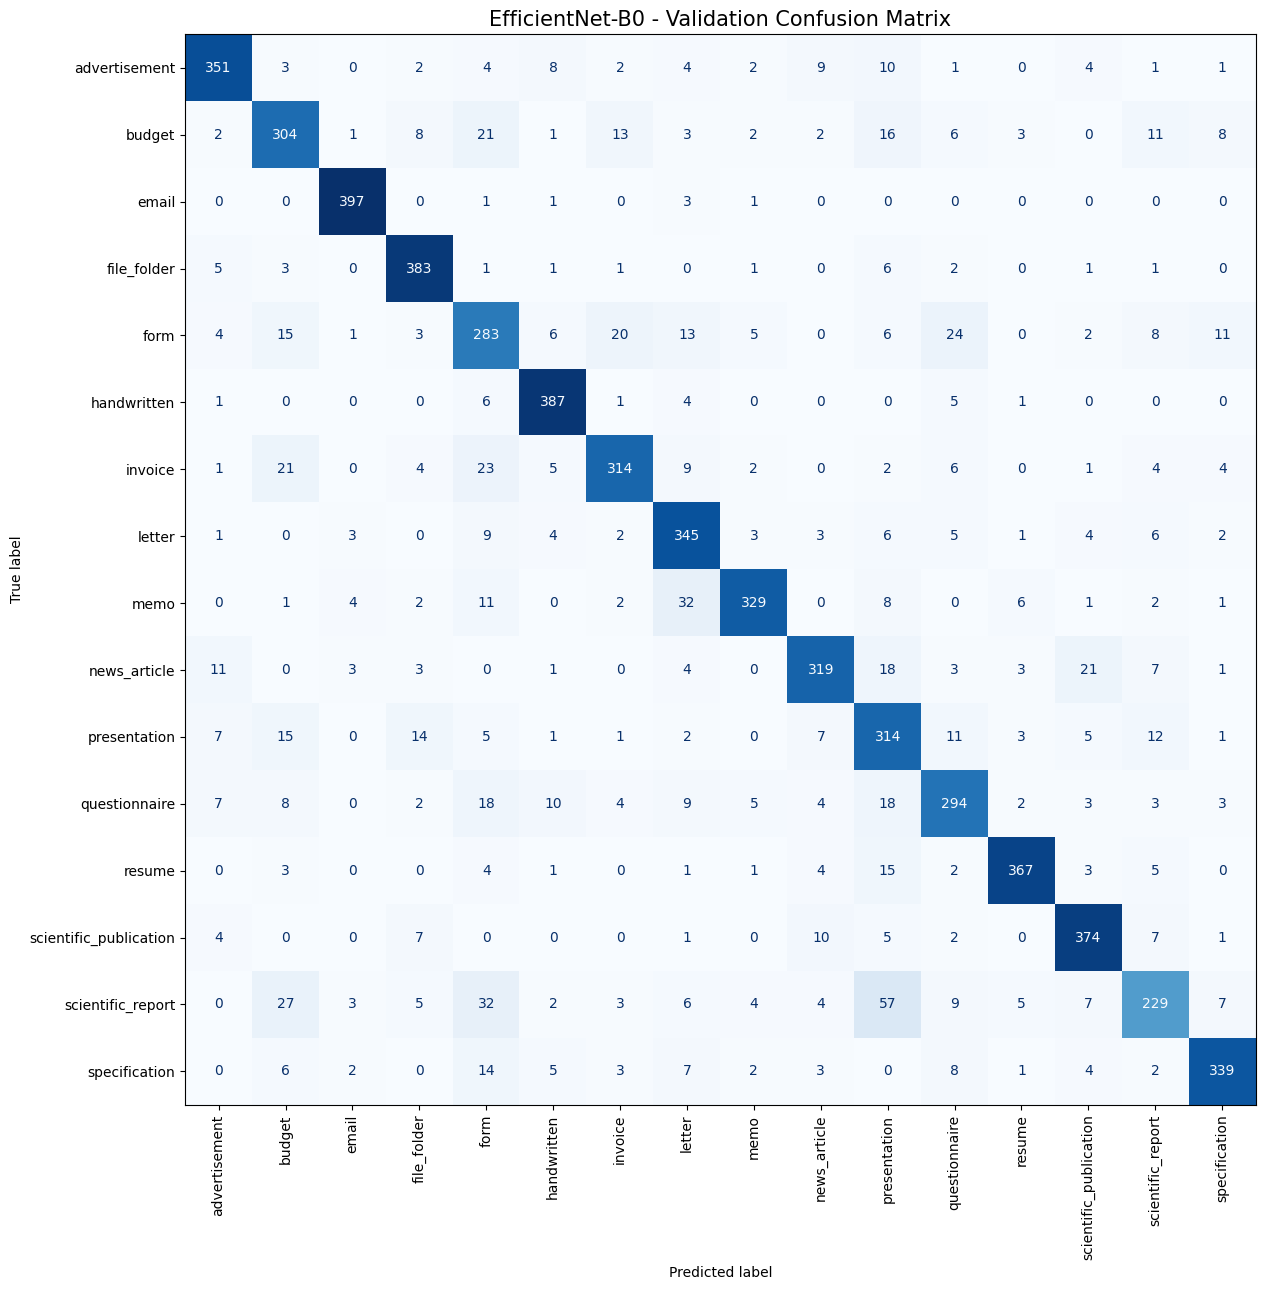


Evaluation files saved!
Location: /kaggle/working/evaluation


In [21]:
# Lokasi best checkpoint
BEST_MODEL_PATH = Path(
    "/kaggle/working/checkpoint/best_efficientnet_b0.pth"
)

assert BEST_MODEL_PATH.exists(), (
    "Checkpoint tidak ditemukan. "
    "Pastikan training sudah selesai."
)

# Memuat model terbaik
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

# Prediksi data validation
with torch.inference_mode():

    for images, labels in tqdm(
        val_loader,
        desc="Evaluating validation data"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(
            labels.cpu().numpy().tolist()
        )

        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

# Nama 16 kelas sesuai label
class_names = (
    train_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")["class_name"]
    .tolist()
)

labels_order = list(range(16))

# Menghitung accuracy
val_accuracy = accuracy_score(y_true, y_pred)

print("=" * 55)
print("EFFICIENTNET-B0 VALIDATION EVALUATION")
print("=" * 55)

print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

# Classification report
report_dict = classification_report(
    y_true,
    y_pred,
    labels=labels_order,
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).T

print("\nClassification Report:")
display(report_df.round(4))

# Simpan classification report
report_df.to_csv(
    EVAL_DIR / "classification_report.csv"
)

# Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels_order
)

fig, ax = plt.subplots(figsize=(15, 13))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "EfficientNet-B0 - Validation Confusion Matrix",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    EVAL_DIR / "confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nEvaluation files saved!")
print("Location:", EVAL_DIR)

In [22]:
# Memilih hanya baris 16 kategori
per_class_report = report_df.loc[class_names].copy()

# Mengurutkan dari F1-score terendah
worst_classes = per_class_report.sort_values(
    by="f1-score",
    ascending=True
)

print("5 KATEGORI DENGAN F1-SCORE TERENDAH")
display(worst_classes.head(5).round(4))

print("\n5 KATEGORI DENGAN F1-SCORE TERTINGGI")
display(worst_classes.tail(5).sort_values(
    by="f1-score",
    ascending=False
).round(4))

5 KATEGORI DENGAN F1-SCORE TERENDAH


,precision,recall,f1-score,support
scientific_report,0.7685,0.5725,0.6562,400.0
form,0.6551,0.7057,0.6795,401.0
presentation,0.6528,0.7889,0.7144,398.0
budget,0.7488,0.7581,0.7534,401.0
questionnaire,0.7778,0.7538,0.7656,390.0



5 KATEGORI DENGAN F1-SCORE TERTINGGI


,precision,recall,f1-score,support
email,0.9589,0.9851,0.9718,403.0
handwritten,0.8938,0.9556,0.9236,405.0
resume,0.9362,0.9039,0.9198,406.0
file_folder,0.8845,0.9457,0.9141,405.0
scientific_publication,0.8698,0.9100,0.8894,411.0


## 4.3 Ekspor Konfigurasi Model

In [23]:
MODEL_CONFIG_PATH = Path(
    "/kaggle/working/model_config.json"
)

# Mengambil epoch terbaik dari history
best_row = history_df.loc[
    history_df["val_acc"].idxmax()
]

model_config = {
    "architecture": "efficientnet_b0",
    "pretrained_source": "imagenet",
    "num_classes": 16,
    "image_size": IMG_SIZE,
    "preprocessing": "resize_with_white_padding",
    "normalization_mean": IMAGENET_MEAN,
    "normalization_std": IMAGENET_STD,
    "class_names": class_names,
    "seed": SEED,
    "best_epoch": int(best_row["epoch"]),
    "best_validation_accuracy": float(
        best_row["val_acc"]
    ),
    "checkpoint_file": "best_efficientnet_b0.pth"
}

# Simpan JSON
with open(
    MODEL_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print("=" * 50)
print("MODEL CONFIGURATION")
print("=" * 50)

print(json.dumps(
    model_config,
    indent=4,
    ensure_ascii=False
))

print("\nConfiguration saved:", MODEL_CONFIG_PATH)

MODEL CONFIGURATION
{
    "architecture": "efficientnet_b0",
    "pretrained_source": "imagenet",
    "num_classes": 16,
    "image_size": 224,
    "preprocessing": "resize_with_white_padding",
    "normalization_mean": [
        0.485,
        0.456,
        0.406
    ],
    "normalization_std": [
        0.229,
        0.224,
        0.225
    ],
    "class_names": [
        "advertisement",
        "budget",
        "email",
        "file_folder",
        "form",
        "handwritten",
        "invoice",
        "letter",
        "memo",
        "news_article",
        "presentation",
        "questionnaire",
        "resume",
        "scientific_publication",
        "scientific_report",
        "specification"
    ],
    "seed": 42,
    "best_epoch": 10,
    "best_validation_accuracy": 83.25261677862834,
    "checkpoint_file": "best_efficientnet_b0.pth"
}

Configuration saved: /kaggle/working/model_config.json


In [24]:
# Verifikasi hasil akhir Notebook 02


OUTPUT_DIR = Path("/kaggle/working")

required_files = [
    "checkpoint/best_efficientnet_b0.pth",
    "training_history.csv",
    "evaluation/training_curves.png",
    "evaluation/classification_report.csv",
    "evaluation/confusion_matrix.png",
    "model_config.json"
]

print("FINAL OUTPUT VERIFICATION")
print("=" * 50)

all_found = True

for filename in required_files:
    path = OUTPUT_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"OK      {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING {filename}")
        all_found = False

if all_found:
    print("\nSemua file evaluasi berhasil disimpan!")
else:
    print("\nMasih ada file yang belum ditemukan.")

FINAL OUTPUT VERIFICATION
OK      checkpoint/best_efficientnet_b0.pth (15.65 MB)
OK      training_history.csv (0.00 MB)
OK      evaluation/training_curves.png (0.12 MB)
OK      evaluation/classification_report.csv (0.00 MB)
OK      evaluation/confusion_matrix.png (0.23 MB)
OK      model_config.json (0.00 MB)

Semua file evaluasi berhasil disimpan!


In [25]:
WORKING_DIR = Path("/kaggle/working")
BUNDLE_PATH = WORKING_DIR / "efficientnet_b0_baseline.zip"

files_to_save = {
    "checkpoint/best_efficientnet_b0.pth":
        WORKING_DIR / "checkpoint/best_efficientnet_b0.pth",
    "model_config.json":
        WORKING_DIR / "model_config.json",
    "training_history.csv":
        WORKING_DIR / "training_history.csv"
}

with zipfile.ZipFile(
    BUNDLE_PATH, "w", zipfile.ZIP_DEFLATED
) as archive:

    for archive_name, file_path in files_to_save.items():
        if not file_path.exists():
            raise FileNotFoundError(file_path)

        archive.write(
            file_path,
            arcname=archive_name
        )

print("Baseline berhasil diarsipkan!")
print("Lokasi:", BUNDLE_PATH)
print(
    "Ukuran:",
    round(BUNDLE_PATH.stat().st_size / 1024**2, 2),
    "MB"
)

Baseline berhasil diarsipkan!
Lokasi: /kaggle/working/efficientnet_b0_baseline.zip
Ukuran: 14.45 MB
